QUESTION 5.2 - PRE VS POST OPTIMISATION
Dataset shape: (144, 14)

Development samples : 115
Held-out test samples: 29

IMPORTANT: The held-out test set is NOT used in Q5.2.

RUNNING VALIDATION COMPARISON

Evaluating: Before Optimisation

Evaluating: After Optimisation


D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty


QUESTION 5.2 - BEFORE VS AFTER OPTIMISATION


D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\Sekomane\Documents\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty

,Model,Accuracy Mean,Accuracy SD,Macro-F1 Mean,Macro-F1 SD,Weighted-F1 Mean,ROC-AUC Mean,PR-AUC Mean
0,Before Optimisation,0.861,0.045,0.815,0.062,0.858,0.861,0.833
1,After Optimisation,0.881,0.037,0.833,0.057,0.875,0.833,0.819



MACRO-F1 IMPROVEMENT
Before optimisation: 0.815
After optimisation : 0.833
Absolute improvement: 0.018
Relative improvement: 2.21 %

CHOSEN HYPERPARAMETERS
C            : 1
Penalty      : L1
Solver       : liblinear
Class weight : None


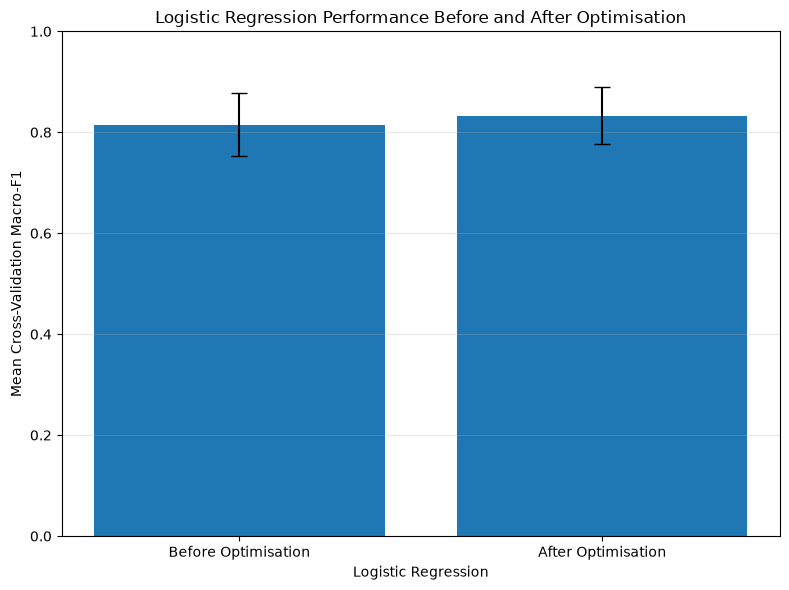


QUESTION 5.2 COMPLETED SUCCESSFULLY

All optimisation comparisons were performed using development-set cross-validation only.
The held-out test set was NOT used for model tuning or model selection.


In [1]:
# =====================================================================
# QUESTION 5.2
# PRE-OPTIMISATION VS POST-OPTIMISATION COMPARISON
# =====================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression


SEED = 42


# =====================================================================
# 1. LOAD DATASET
# =====================================================================

PATH = r"C:\Users\Sekomane\Desktop\Data ScienceTUT\NIWIS_Water Supply Reliability - Population_26-Sep-2026.csv"

df = pd.read_csv(PATH)

print("=" * 80)
print("QUESTION 5.2 - PRE VS POST OPTIMISATION")
print("=" * 80)

print("Dataset shape:", df.shape)


# =====================================================================
# 2. CLEAN DATA
# =====================================================================

data = df.copy()

# Remove empty unnamed columns
data = data.loc[
    :,
    ~data.columns.str.contains("^Unnamed")
]


# Standardise spaces in column names
data.columns = (
    data.columns
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
)


def clean_number(series):

    return pd.to_numeric(
        series.astype(str)
              .str.replace(" ", "", regex=False)
              .str.replace(",", "", regex=False)
              .str.strip(),
        errors="coerce"
    )


# Convert count/population columns
for col in data.columns:

    if "%" not in col and col != "WSA Name":

        data[col] = clean_number(
            data[col]
        )


# Convert percentage columns
for col in data.columns:

    if "%" in col:

        data[col] = pd.to_numeric(
            data[col]
                .astype(str)
                .str.replace("%", "", regex=False)
                .str.strip(),
            errors="coerce"
        )


# =====================================================================
# 3. CREATE TARGET
# =====================================================================

# Class 0 = Reliable (>= 60%)
# Class 1 = Low Reliability (< 60%)

data["low_reliability"] = (
    data["% Population Reliable Supply"] < 60
).astype(int)


# =====================================================================
# 4. REMOVE LEAKAGE
# =====================================================================

leakage_columns = [

    "Population Reliable Supply",
    "% Population Reliable Supply",

    "Urban Population Reliable Supply",
    "% Urban Population Reliable Supply",

    "Rural Population Reliable Supply",
    "% Rural Population Reliable Supply"
]


y = data["low_reliability"]


X = data.drop(
    columns=[
        "low_reliability",
        "WSA Name"
    ] + leakage_columns,
    errors="ignore"
).copy()


# =====================================================================
# 5. FEATURE ENGINEERING
# =====================================================================

X["population_access_rate"] = (
    X["Population with access to water"]
    / X["Population"]
) * 100


X["urban_access_rate"] = (
    X["Urban Population with access to water"]
    / X["Urban Population"]
) * 100


X["rural_access_rate"] = (
    X["Rural Population with access to water"]
    / X["Rural Population"]
) * 100


X["urban_population_share"] = (
    X["Urban Population"]
    / X["Population"]
) * 100


X["rural_population_share"] = (
    X["Rural Population"]
    / X["Population"]
) * 100


X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# =====================================================================
# 6. DEVELOPMENT / TEST SPLIT
# =====================================================================

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)


print("\nDevelopment samples :", len(X_dev))
print("Held-out test samples:", len(X_test))

print(
    "\nIMPORTANT: The held-out test set is NOT used in Q5.2."
)


# =====================================================================
# 7. ORIGINAL LOGISTIC REGRESSION
# =====================================================================

# This is the original model used before optimisation.

original_model = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),

    (
        "scaler",
        RobustScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED
        )
    )
])


# =====================================================================
# 8. OPTIMISED LOGISTIC REGRESSION
# =====================================================================

# Best hyperparameters obtained in Q5.1:
#
# C = 1
# class_weight = None
# penalty = L1
# solver = liblinear

optimized_model = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),

    (
        "scaler",
        RobustScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            C=1,
            penalty="l1",
            solver="liblinear",
            class_weight=None,
            max_iter=5000,
            random_state=SEED
        )
    )
])


# =====================================================================
# 9. SAME CROSS-VALIDATION FOR BOTH MODELS
# =====================================================================

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)


scoring = {

    "accuracy":
        "accuracy",

    "macro_f1":
        "f1_macro",

    "weighted_f1":
        "f1_weighted",

    "roc_auc":
        "roc_auc",

    "pr_auc":
        "average_precision"
}


models = {

    "Before Optimisation":
        original_model,

    "After Optimisation":
        optimized_model
}


# =====================================================================
# 10. CROSS-VALIDATION COMPARISON
# =====================================================================

results = []


print("\n" + "=" * 80)
print("RUNNING VALIDATION COMPARISON")
print("=" * 80)


for model_name, model in models.items():

    print(
        f"\nEvaluating: {model_name}"
    )


    scores = cross_validate(
        model,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )


    results.append({

        "Model":
            model_name,

        "Accuracy Mean":
            scores["test_accuracy"].mean(),

        "Accuracy SD":
            scores["test_accuracy"].std(),

        "Macro-F1 Mean":
            scores["test_macro_f1"].mean(),

        "Macro-F1 SD":
            scores["test_macro_f1"].std(),

        "Weighted-F1 Mean":
            scores["test_weighted_f1"].mean(),

        "ROC-AUC Mean":
            scores["test_roc_auc"].mean(),

        "PR-AUC Mean":
            scores["test_pr_auc"].mean()
    })


# =====================================================================
# 11. CREATE COMPARISON TABLE
# =====================================================================

comparison_df = pd.DataFrame(
    results
)


numeric_columns = comparison_df.select_dtypes(
    include=np.number
).columns


comparison_df[numeric_columns] = (
    comparison_df[numeric_columns]
        .round(3)
)


print("\n" + "=" * 90)
print("QUESTION 5.2 - BEFORE VS AFTER OPTIMISATION")
print("=" * 90)


display(
    comparison_df
)


# =====================================================================
# 12. CALCULATE IMPROVEMENT
# =====================================================================

before_macro_f1 = comparison_df.loc[
    comparison_df["Model"] == "Before Optimisation",
    "Macro-F1 Mean"
].iloc[0]


after_macro_f1 = comparison_df.loc[
    comparison_df["Model"] == "After Optimisation",
    "Macro-F1 Mean"
].iloc[0]


absolute_improvement = (
    after_macro_f1
    - before_macro_f1
)


relative_improvement = (
    absolute_improvement
    / before_macro_f1
) * 100


print("\n" + "=" * 80)
print("MACRO-F1 IMPROVEMENT")
print("=" * 80)


print(
    "Before optimisation:",
    before_macro_f1
)


print(
    "After optimisation :",
    after_macro_f1
)


print(
    "Absolute improvement:",
    round(
        absolute_improvement,
        3
    )
)


print(
    "Relative improvement:",
    round(
        relative_improvement,
        2
    ),
    "%"
)


# =====================================================================
# 13. REPORT CHOSEN HYPERPARAMETERS
# =====================================================================

print("\n" + "=" * 80)
print("CHOSEN HYPERPARAMETERS")
print("=" * 80)


print("C            : 1")
print("Penalty      : L1")
print("Solver       : liblinear")
print("Class weight : None")


# =====================================================================
# 14. BAR CHART
# =====================================================================

plt.figure(
    figsize=(8, 6)
)


plt.bar(
    comparison_df["Model"],
    comparison_df["Macro-F1 Mean"],
    yerr=comparison_df["Macro-F1 SD"],
    capsize=6
)


plt.ylabel(
    "Mean Cross-Validation Macro-F1"
)


plt.xlabel(
    "Logistic Regression"
)


plt.title(
    "Logistic Regression Performance Before and After Optimisation"
)


plt.ylim(
    0,
    1
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()


# =====================================================================
# 15. FINAL MESSAGE
# =====================================================================

print("\n" + "=" * 80)

print(
    "QUESTION 5.2 COMPLETED SUCCESSFULLY"
)

print("=" * 80)


print(
    "\nAll optimisation comparisons were performed using "
    "development-set cross-validation only."
)


print(
    "The held-out test set was NOT used for model tuning "
    "or model selection."
)